# 第5章 储冷容量配置与滚动控制

全部数据为教学构造数据。先安装仓库requirements.txt、requirements-viz.txt与Jupyter/IPython。五个代码单元依次执行，完整实验使用新的临时目录。交互演示见demo/ch05/教学演示.html。

## 1 边界与冷量换算

检查热功率、电功率与库存单位；正常出口6 ℃、回水12 ℃、有效系数0.85。

In [1]:
from pathlib import Path
import sys, tempfile, json, importlib.util
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapters/ch05/run.py").exists())
chapter = root / "chapters/ch05"
sys.path.insert(0, str(chapter))
spec = importlib.util.spec_from_file_location("ch05_model", chapter / "run.py")
model = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = model
spec.loader.exec_module(model)
assert abs(model.capacity(20) - 118.43333333333334) < 1e-8
print(f"20 m³有效容量：{model.capacity(20):.6f} kWh")
print(f"2 kg/s、6 K温差供冷：{2*4.18*6:.2f} kW")

20 m³有效容量：118.433333 kWh
2 kg/s、6 K温差供冷：50.16 kW


## 2 冻结预测器并核验信息时序

标准化与回归只使用28个训练日，7个验证日选参数。未来实际值用于运行后评价。

In [2]:
import copy
import numpy as np
train, validation, days = model.dataset()
forecaster, training = model.train_forecaster(train, validation)
print("训练/验证时段：", training["training_rows"], training["validation_rows"])
print("选中的alpha：", training["selected_alpha"])
day = next(d for d in days if d["key"] == "heatwave")
base, _ = model.forecast(forecaster, day, 10, 12)
changed = copy.deepcopy(day)
changed["load"][11:] += 100
changed["temp"][11:] += 20
again, _ = model.forecast(forecaster, changed, 10, 12)
np.testing.assert_array_equal(base, again)
print("未来实际数据变化后，当前发布预测保持相同。")

训练/验证时段： 672 168
选中的alpha： 1
未来实际数据变化后，当前发布预测保持相同。


## 3 重新计算全部113条轨迹

同时保留费用、服务不足、求解状态与完整滚动计划。每次执行建立新目录。

In [3]:
work = tempfile.TemporaryDirectory(prefix="ch05_notebook_")
out = Path(work.name) / "experiment"
data = model.experiment()
summary = model.write_outputs(out, data)
print("方案数：", len(data["runs"]))
for run in data["runs"]:
    if run["scenario"] == "hot" and run["volume"] == 20:
        print(run["policy"], {k: round(v,4) if isinstance(v,(int,float)) else v
              for k,v in run["metrics"].items()})

Finished cool
Finished mild
Finished hot
Finished heatwave
Finished quality
方案数： 113
rule {'electricity_cost_cny': 150.6509, 'unmet_kwh': 7.5814, 'objective_cny': 908.7925, 'electricity_kwh': 207.8263, 'peak_electric_kw': 11.3643, 'unmet_hours': 2, 'end_inventory_kwh': 0.0, 'max_supply_c': 6.0, 'max_loop_flow_kg_s': 2.4487, 'max_balance_residual_kwh': 0.0}
perfect {'electricity_cost_cny': 152.2717, 'unmet_kwh': 0.0, 'objective_cny': 152.2717, 'electricity_kwh': 209.3223, 'peak_electric_kw': 11.4304, 'unmet_hours': 0, 'end_inventory_kwh': 0.0, 'max_supply_c': 6.0, 'max_loop_flow_kg_s': 2.4487, 'max_balance_residual_kwh': 0.0}
mpc {'electricity_cost_cny': 151.6465, 'unmet_kwh': 2.8224, 'objective_cny': 433.8859, 'electricity_kwh': 208.779, 'peak_electric_kw': 11.4017, 'unmet_hours': 1, 'end_inventory_kwh': 0.0, 'max_supply_c': 6.0, 'max_loop_flow_kg_s': 2.4487, 'max_balance_residual_kwh': 0.0}


## 4 把费用与服务结果并列

权重150/120/90/5日，日初末均为空罐。年化投资是本章教学假设。

In [4]:
rows = [r for r in data["annual"]["rows"] if r["policy"] == "mpc"]
for row in rows:
    print(f"{row['volume']:2d} m³ | {row['weighted_total_cost_cny']:.2f} 元 | "
          f"未满足 {row['weighted_unmet_kwh']:.2f} kWh")
best = min(rows, key=lambda r: r["weighted_total_cost_cny"])
print("本候选集费用最低点：", best["volume"], "m³")
assert best["volume"] == 40
assert best["weighted_unmet_kwh"] > 218

 0 m³ | 48981.89 元 | 未满足 3729.65 kWh
10 m³ | 48367.57 元 | 未满足 852.03 kWh
20 m³ | 46385.73 元 | 未满足 574.18 kWh
30 m³ | 44595.69 元 | 未满足 218.17 kWh
40 m³ | 43829.20 元 | 未满足 218.17 kWh
50 m³ | 44175.76 元 | 未满足 218.17 kWh
60 m³ | 44753.82 元 | 未满足 218.17 kWh
本候选集费用最低点： 40 m³


## 5 重绘六幅定量图

读取刚刚生成的同一份结果，导出SVG、PDF与600 dpi PNG。先查看三种策略的逐时调度。

六幅定量图已生成。数值核验：python chapters/ch05/verify.py


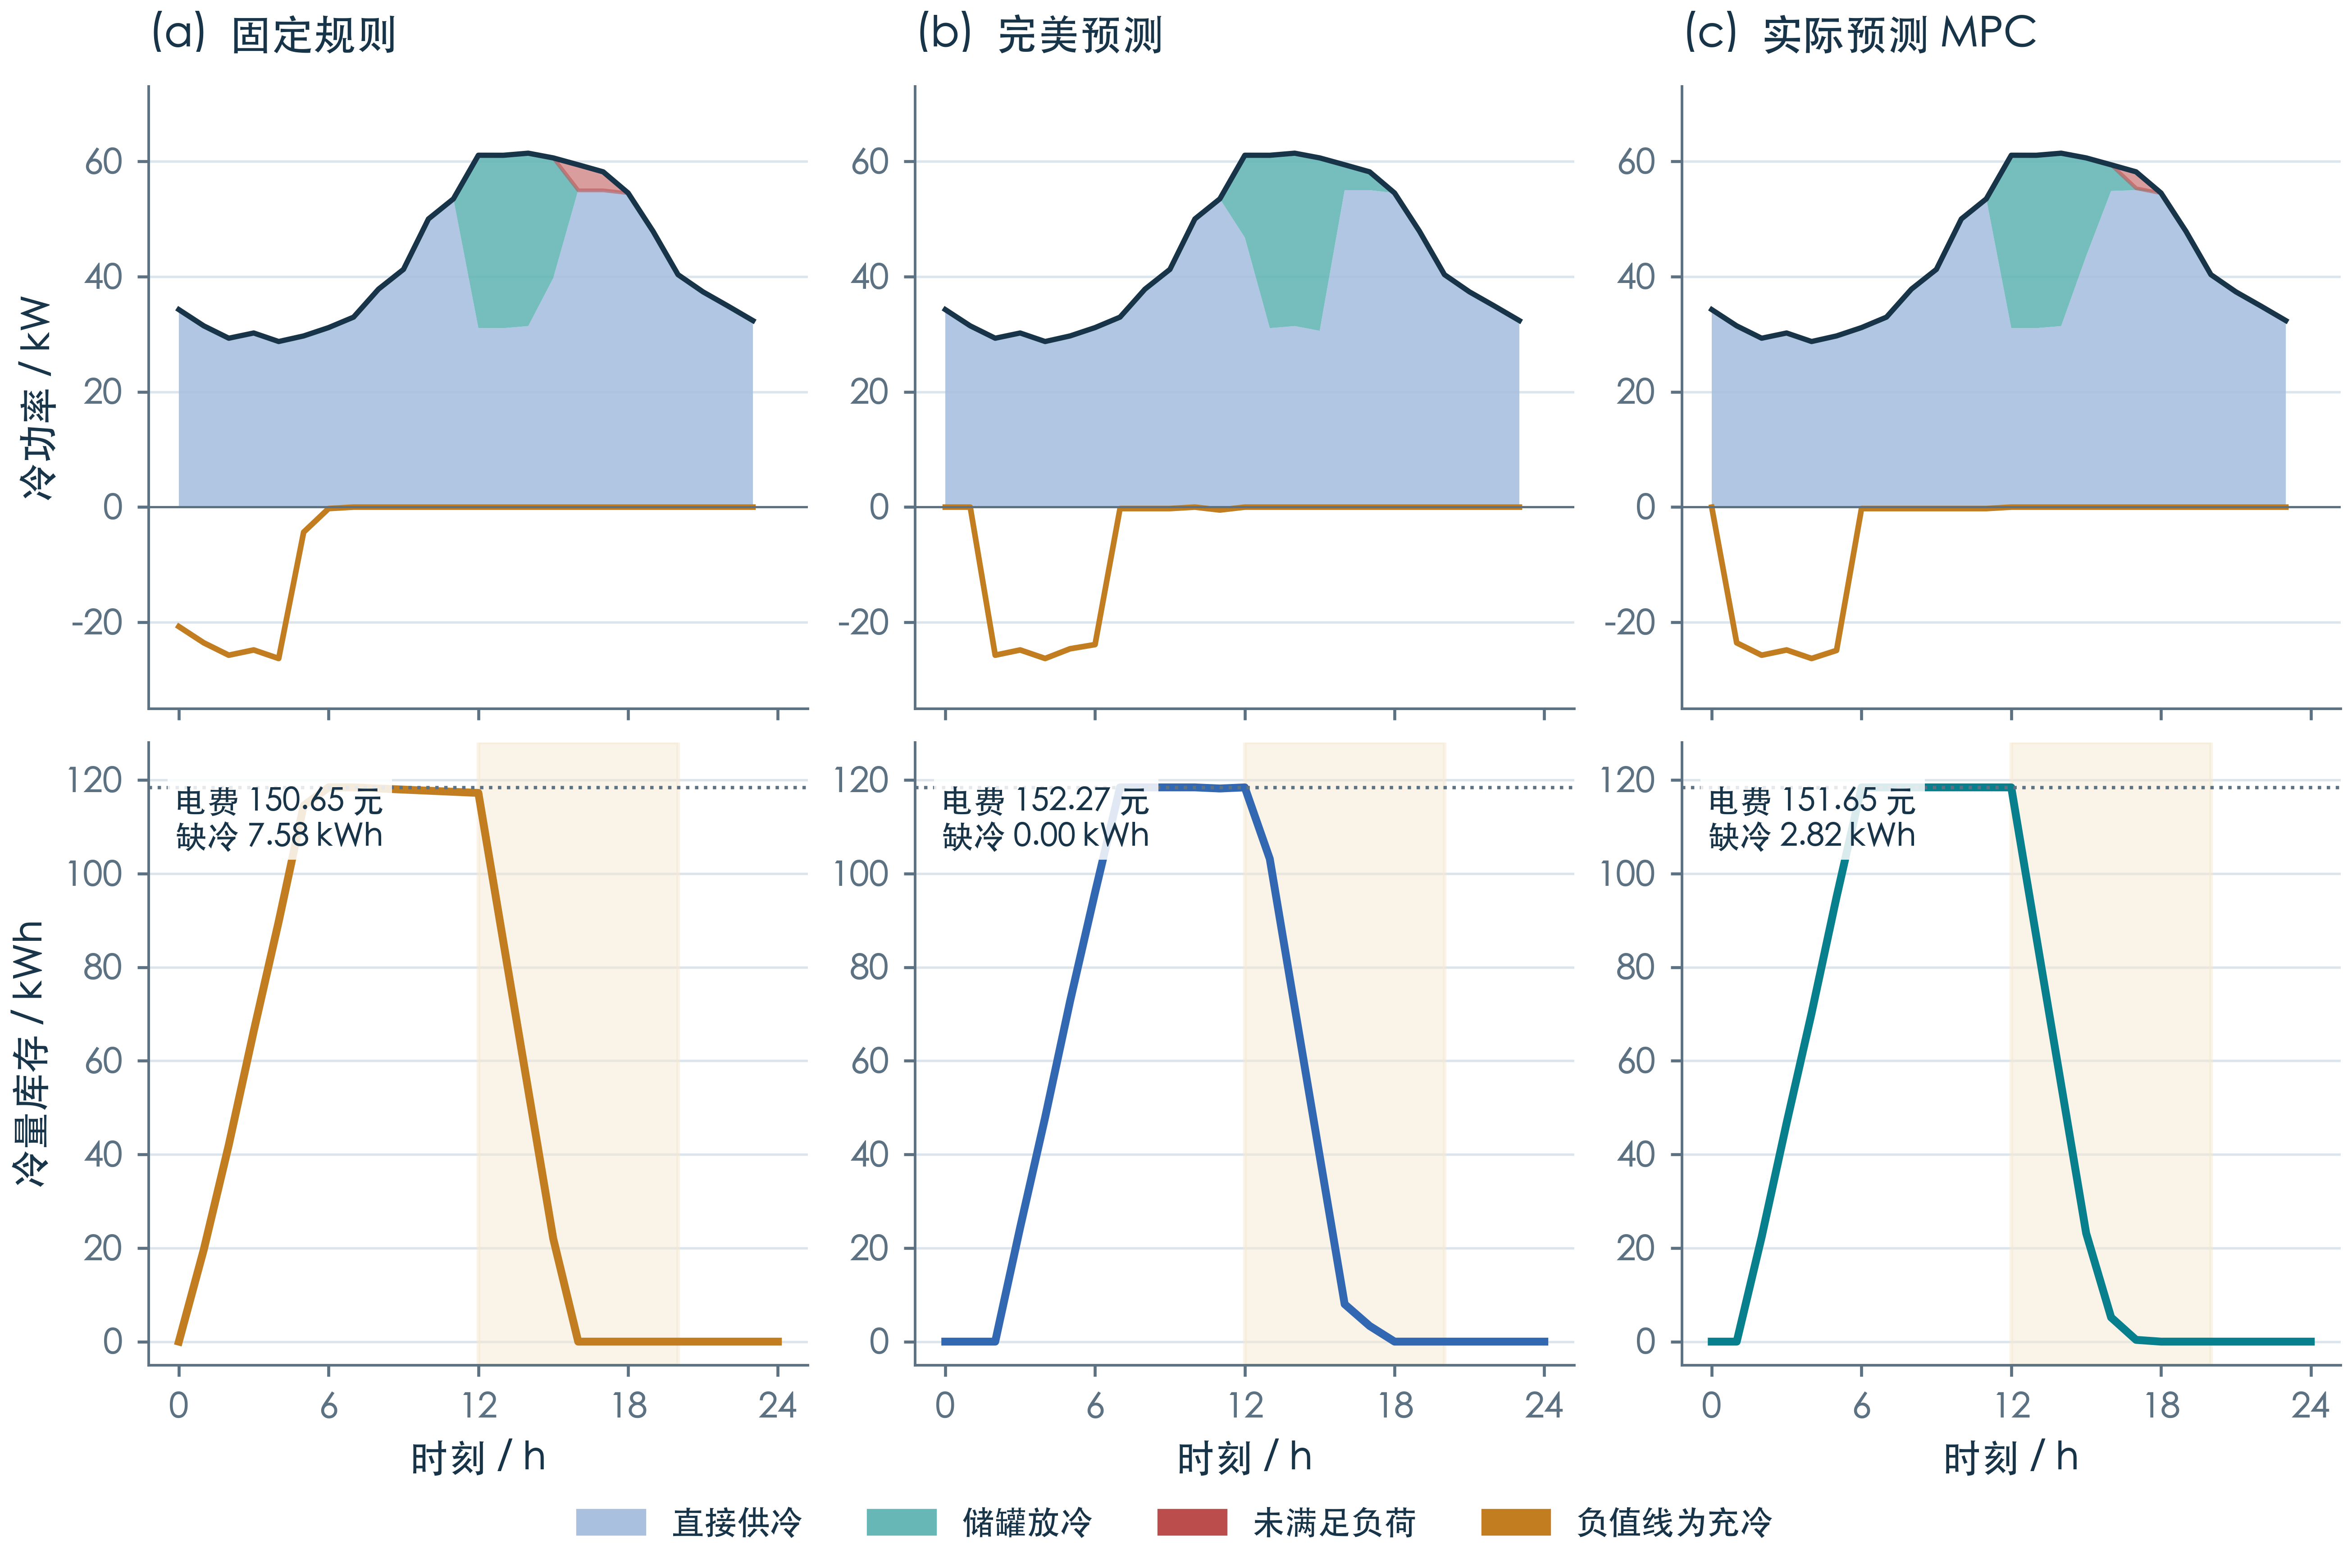

In [5]:
from plot_results import draw
from IPython.display import Image, display
draw(data, out / "figures")
display(Image(filename=str(out / "figures/fig5_5_dispatch.png"), width=950))
print("六幅定量图已生成。数值核验：python chapters/ch05/verify.py")

## 继续实验

在新配置中分别改变冷机能力、接口功率或回路流量，并保留原始参数作对照。也可比较终端库存目标与较短时域。每次只改变有解释的条件，记录费用、未满足冷量与温度资格。原理图脚本为draw_diagrams.py；网页方案库由build_demo.py读取计算输出生成。